# Session 3, Part 2 (Finger-tapping sequence learning): early vs late

One continuous recording of a finger-tapping sequence task, noted as running from
**7:24:51 to 7:32:27 PM**, with a **cough at 7:30:58 PM**.

**Hypothesis:** as the sequence is learned it needs less mental effort, so frontal theta should
**fall** and parietal alpha **rise** from early to late in the task. In motor-learning studies,
frontal theta drops as a task becomes familiar.

**Caveat specific to this design:** "early vs late" is also "fresh vs tired". Fatigue raises
alpha too, and theta can rise with time on task, so a change over time can't be credited to
learning alone without performance data (tapping speed and errors).

**Same recording setup as Part 1:** Fz is dead (saturated for the whole session), so frontal
theta is measured at **F3+F4**; M1/M2 are excluded; all analysis is average-referenced;
sampled at 1000 Hz. p-values are descriptive only.

Shared analysis code: `processing/analysis.py` and `processing/cleaning.py`.

In [1]:
import sys
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session
from processing.analysis import (
    band_filter, periodic_metrics, periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars,
    plot_quality, plot_relative_bars, plot_segments, plot_spectra, roi_spectrum, window_spectra,
)
from processing.cleaning import ica_clean, prepare

plt.rcParams["figure.dpi"] = 72

SESSION_DIR = REPO_ROOT / "data" / "Session 3_ pt2"
BAD_CHANNELS = ["Fz", "M1", "M2"]   # Fz saturated (no contact); mastoids noisy
THETA_SITE, THETA_CHANNELS = "F3+F4", ["F3", "F4"]   # stands in for Fz
ALPHA_SITE = "Pz"
LOCAL_UTC_OFFSET = timedelta(hours=-5)   # EST
NOTED = {"task start": "19:24:51", "cough": "19:30:58", "task end": "19:32:27"}   # from the session notes
N_BLOCKS = 6

In [2]:
session = load_session(SESSION_DIR)
recording = session.segments[0]
start_local = session.raw.info["meas_date"].replace(tzinfo=None) + LOCAL_UTC_OFFSET
end_local = start_local + timedelta(seconds=recording.times[-1])
print(f"Recording (eego clock): {start_local:%H:%M:%S} to {end_local:%H:%M:%S} local, {recording.times[-1]:.1f} s at {session.sfreq:g} Hz")

Recording (eego clock): 19:24:29 to 19:32:14 local, 465.5 s at 1000 Hz


## 1. Aligning the session notes with the recording

The noted end time (7:32:27) is 13 s after the recording stops (7:32:14 by the eego laptop's
clock), so the two clocks don't agree. A cough produces a large burst on every channel at once,
so finding it in the data gives the offset.

**Why this plot:** it shows the overall signal level second by second, so the cough (and the
setup activity before tapping started) can be located in the recording rather than assumed from the notes.

Largest burst after the first minute: 377 s into the recording (19:30:46 on the eego clock)
Noted cough time is 389 s into the recording → the notes' clock is about 12 s ahead
  task start noted 19:24:51 →   10.0 s into the recording
  cough      noted 19:30:58 →  377.0 s into the recording
  task end   noted 19:32:27 →  466.0 s into the recording


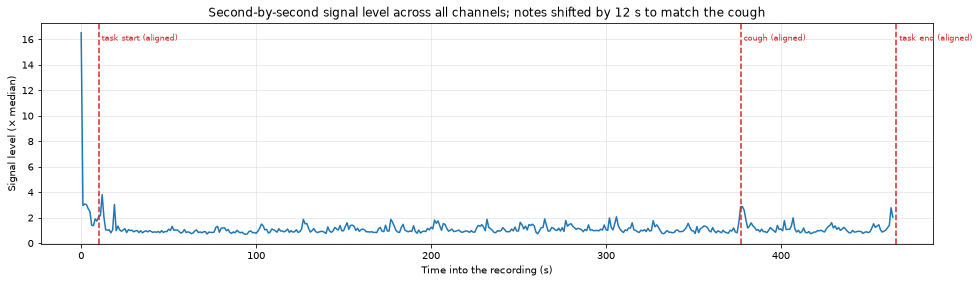

Analysis uses 10.0 s to the end of the recording, excluding 375–382 s (cough)


In [3]:
x = recording.copy().filter(1, 40, verbose="error").get_data() * 1e6
level = np.median(np.abs(x), axis=0)   # median over channels: only rises when most channels move together
del x
sf = int(session.sfreq)
level_1s = level[: len(level) // sf * sf].reshape(-1, sf).mean(axis=1)
level_1s /= np.median(level_1s)

# The cough: the largest burst after the first minute (the start is dominated by setup activity)
search = slice(60, len(level_1s))
cough_t = int(np.argmax(level_1s[search]) + search.start)
noted_cough = (pd.Timestamp(f"{start_local:%Y-%m-%d} {NOTED['cough']}") - pd.Timestamp(start_local)).total_seconds()
offset = noted_cough - cough_t
print(f"Largest burst after the first minute: {cough_t} s into the recording ({start_local + timedelta(seconds=cough_t):%H:%M:%S} on the eego clock)")
print(f"Noted cough time is {noted_cough:.0f} s into the recording → the notes' clock is about {offset:.0f} s ahead")
aligned = {k: (pd.Timestamp(f"{start_local:%Y-%m-%d} {v}") - pd.Timestamp(start_local)).total_seconds() - offset for k, v in NOTED.items()}
for k, t in aligned.items():
    print(f"  {k:10} noted {NOTED[k]} → {t:6.1f} s into the recording")

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(np.arange(len(level_1s)), level_1s, color="C0")
for k, t in aligned.items():
    ax.axvline(t, color="C3", ls="--")
    ax.text(t, ax.get_ylim()[1] * 0.95, f" {k} (aligned)", color="C3", fontsize=8, va="top")
ax.set_xlabel("Time into the recording (s)")
ax.set_ylabel("Signal level (× median)")
ax.set_title(f"Second-by-second signal level across all channels; notes shifted by {offset:.0f} s to match the cough")
ax.grid(alpha=0.3)
plt.show()

TASK_START = max(0.0, aligned["task start"])
COUGH = (cough_t - 2.0, cough_t + 5.0)   # excluded from analysis
print(f"Analysis uses {TASK_START:.1f} s to the end of the recording, excluding {COUGH[0]:.0f}–{COUGH[1]:.0f} s (cough)")

## 2. Data quality across the task

The task portion is prepared (Fz, M1, M2 dropped; 1–100 Hz; 60 Hz notch; average reference),
the cough is marked as bad, and the task is split into six equal blocks.

**Why this plot:** it shows whether some part of the task (for example around the cough) or some
channels have too little clean EEG to trust.

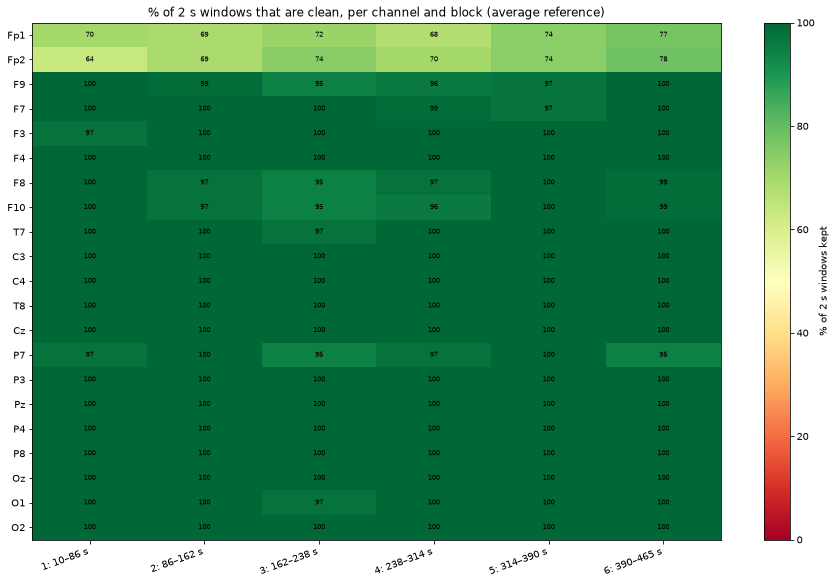

In [4]:
prepared = prepare(recording, BAD_CHANNELS)
task = prepared.copy().crop(tmin=TASK_START, verbose="error")
task.annotations.append(COUGH[0], COUGH[1] - COUGH[0], "BAD_cough")
block_len = task.times[-1] / N_BLOCKS


def split(raw, n):
    length = raw.times[-1] / n
    return [raw.copy().crop(tmin=b * length, tmax=(b + 1) * length, include_tmax=False, verbose="error") for b in range(n)]


def block_name(b, n=N_BLOCKS):
    length = task.times[-1] / n
    return f"{b + 1}: {TASK_START + b * length:.0f}–{TASK_START + (b + 1) * length:.0f} s"


blocks = split(task, N_BLOCKS)
plot_quality([window_spectra(b) for b in blocks], [block_name(b) for b in range(N_BLOCKS)],
             "% of 2 s windows that are clean, per channel and block (average reference)")

## 3. Band plots: first third vs last third of the task

The first third of the task on the left, the last third on the right (each about 2.5 minutes).
The shaded span in the right column is the cough, excluded from the analysis.

In [5]:
thirds = split(task, 3)
raw_task = recording.copy().drop_channels(BAD_CHANNELS).crop(tmin=TASK_START, verbose="error")
raw_thirds = split(raw_task, 3)
third_labels = [f"Early: first third ({TASK_START:.0f}–{TASK_START + task.times[-1] / 3:.0f} s)",
                f"Late: last third ({TASK_START + 2 * task.times[-1] / 3:.0f}–{TASK_START + task.times[-1]:.0f} s)"]
late_start = TASK_START + 2 * task.times[-1] / 3
marks = [[], [(COUGH[0] - late_start, COUGH[1] - late_start, "cough")]]
early_late = [thirds[0], thirds[2]]

### 3.1 Original data (no filtering, original reference)

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

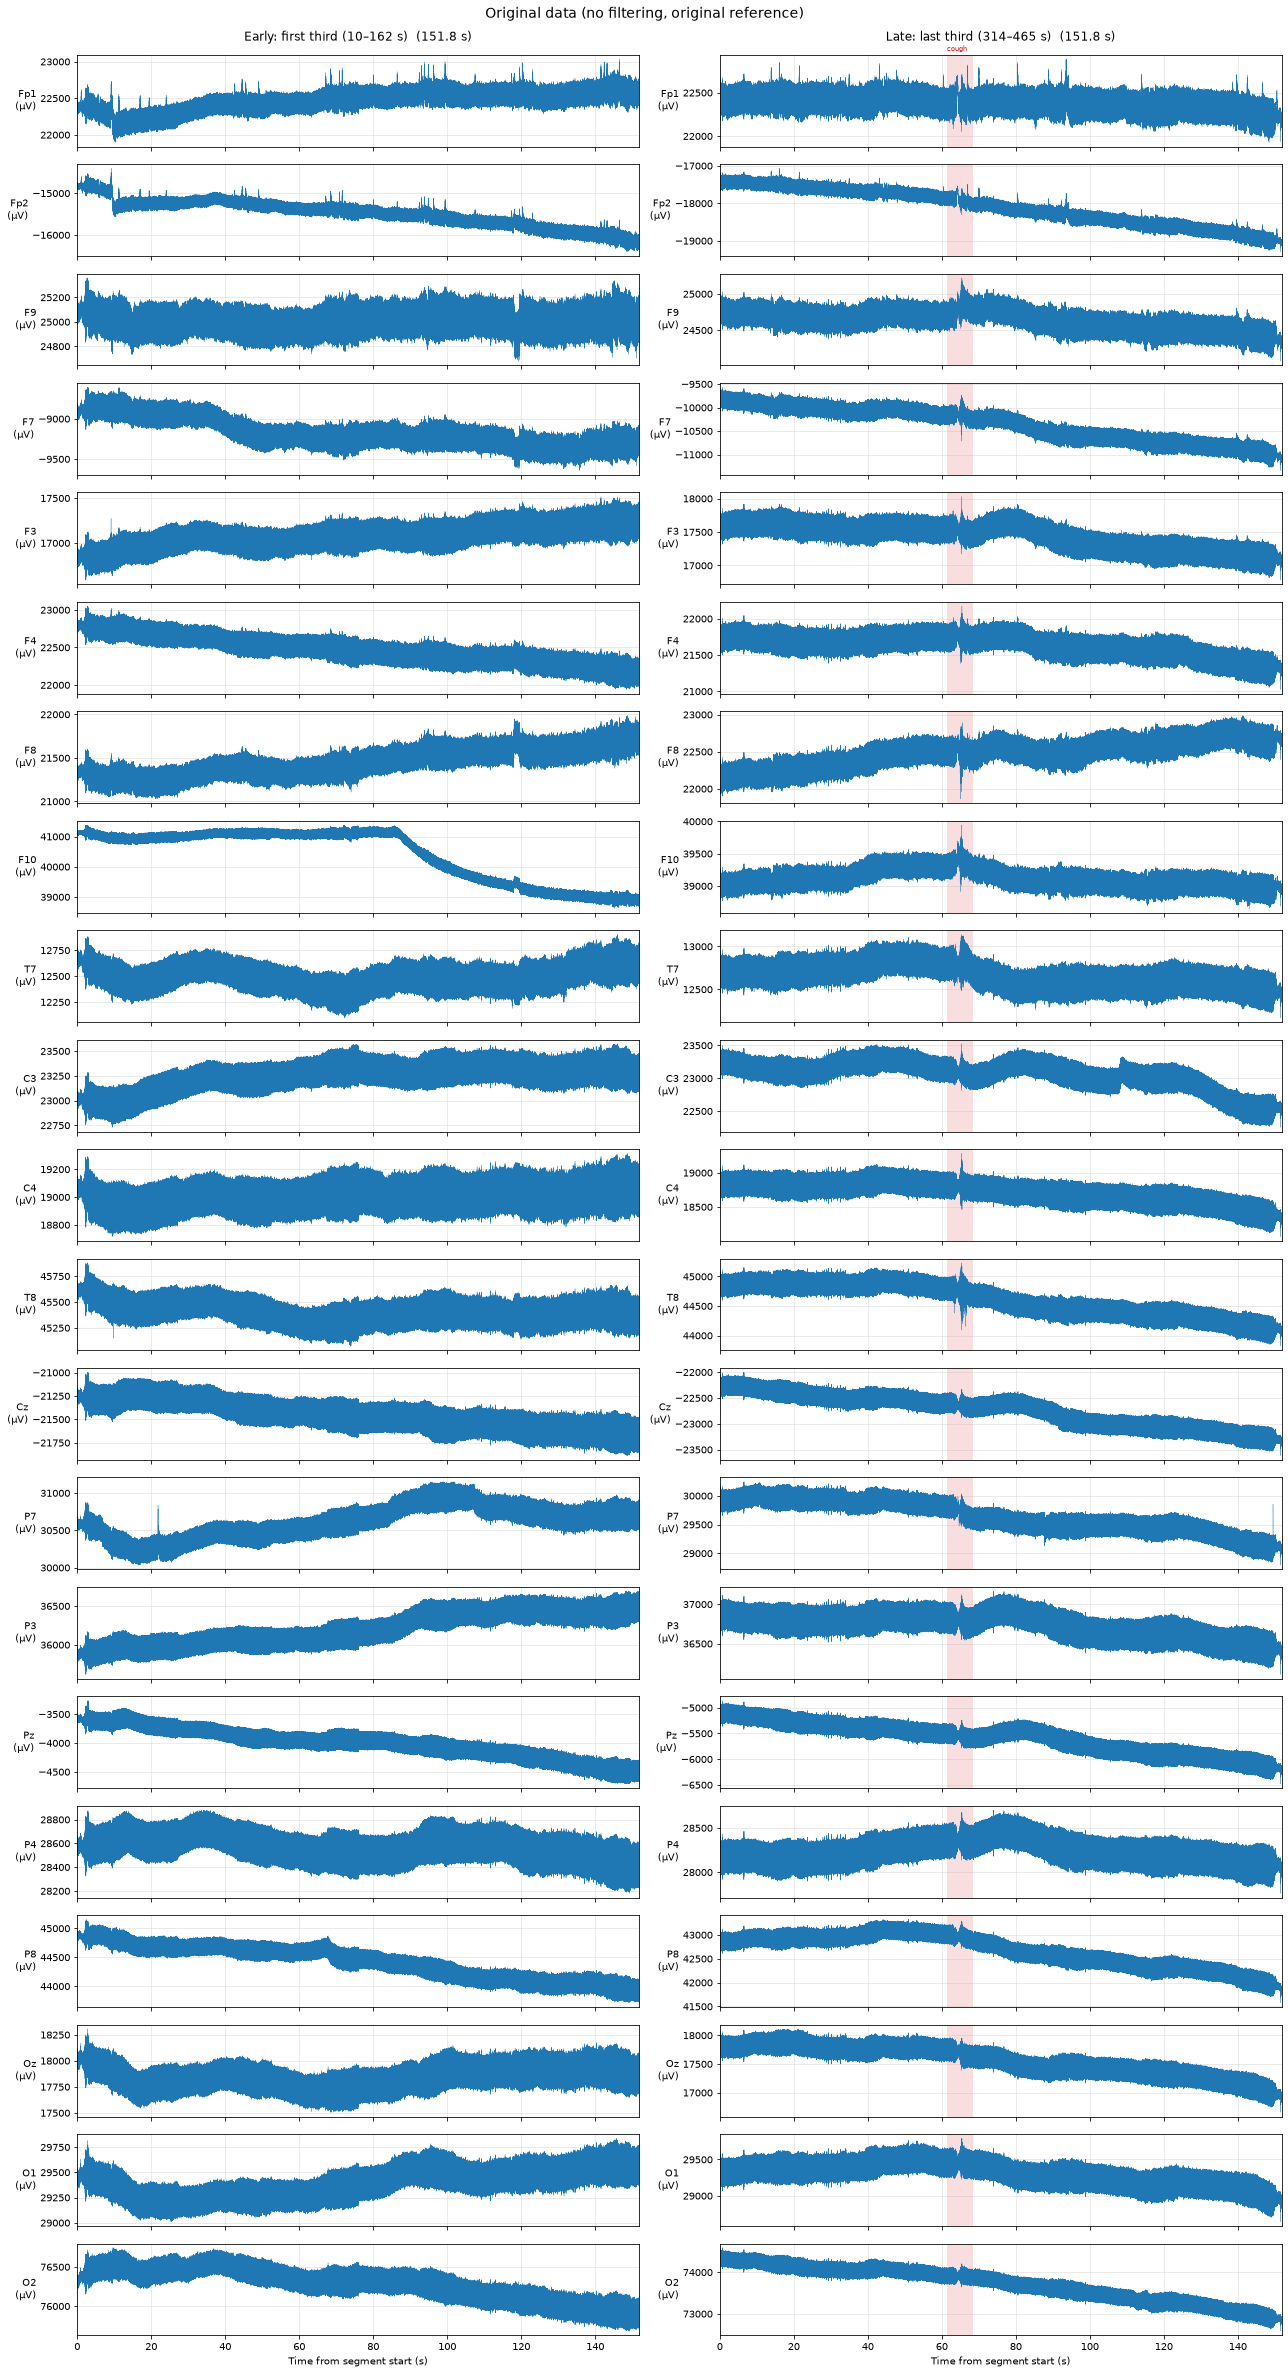

In [6]:
plot_segments([raw_thirds[0], raw_thirds[2]], third_labels, "Original data (no filtering, original reference)", sharey_rows=False, marks=marks)

### 3.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta (here F3/F4) falls as a task becomes familiar, so lower theta late in the task would suggest the sequence needed less effort.

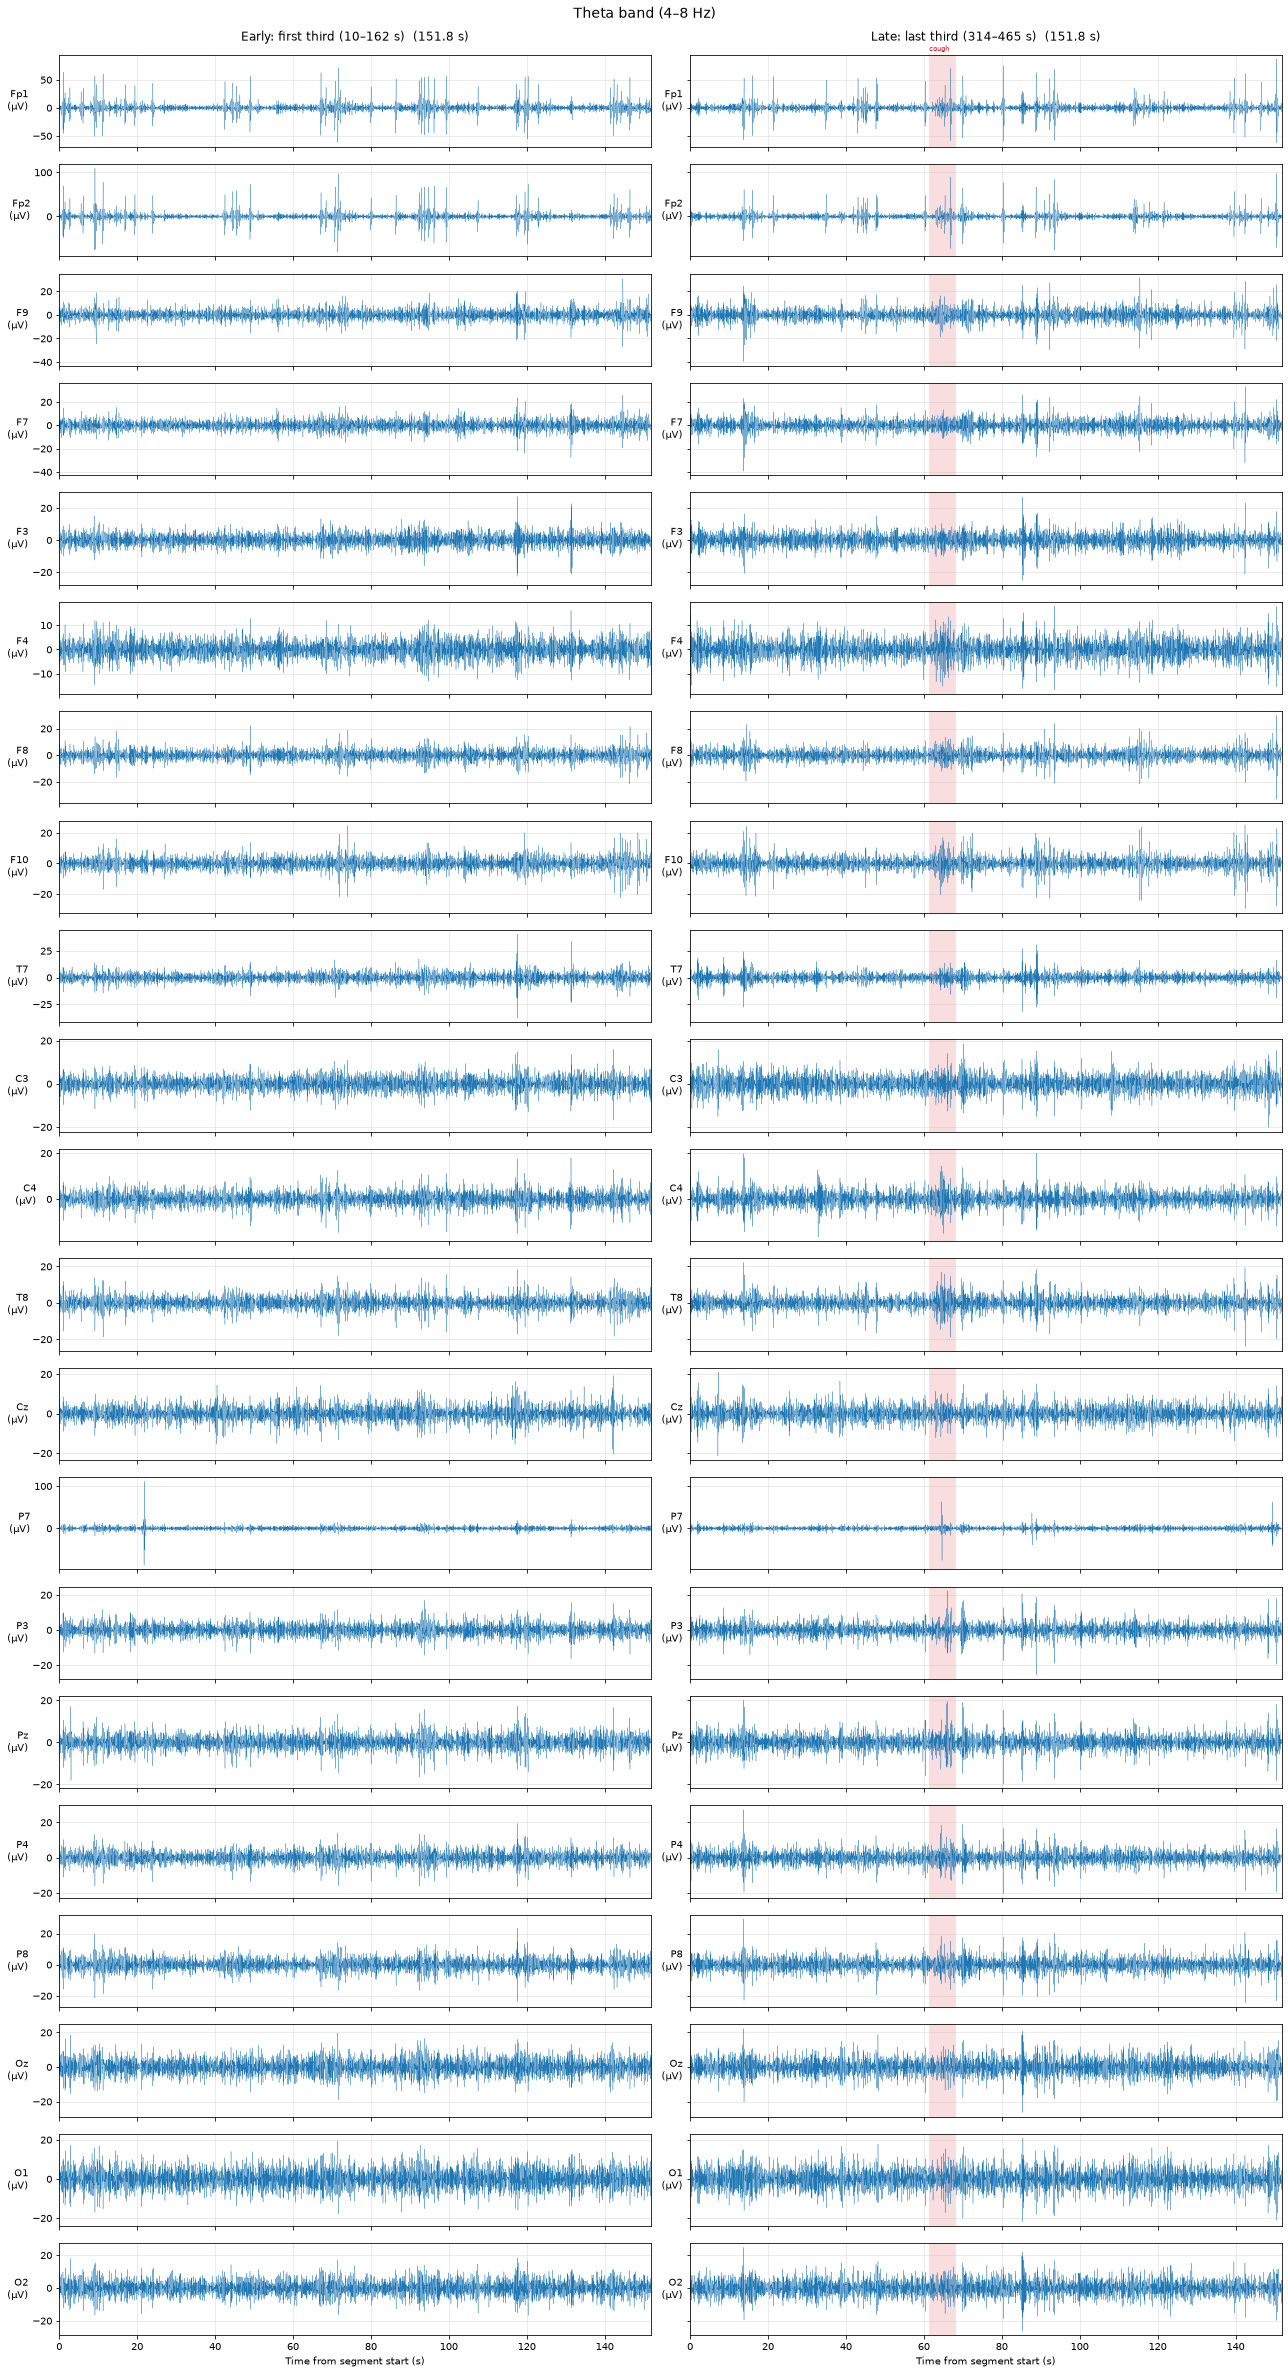

In [7]:
plot_segments([band_filter(s, 4, 8) for s in early_late], third_labels, "Theta band (4–8 Hz)", marks=marks)

### 3.3 Alpha band (8–13 Hz)

**Why this plot:** parietal alpha rises as a task needs less attention (but also with fatigue), so higher alpha late in the task would fit learning.

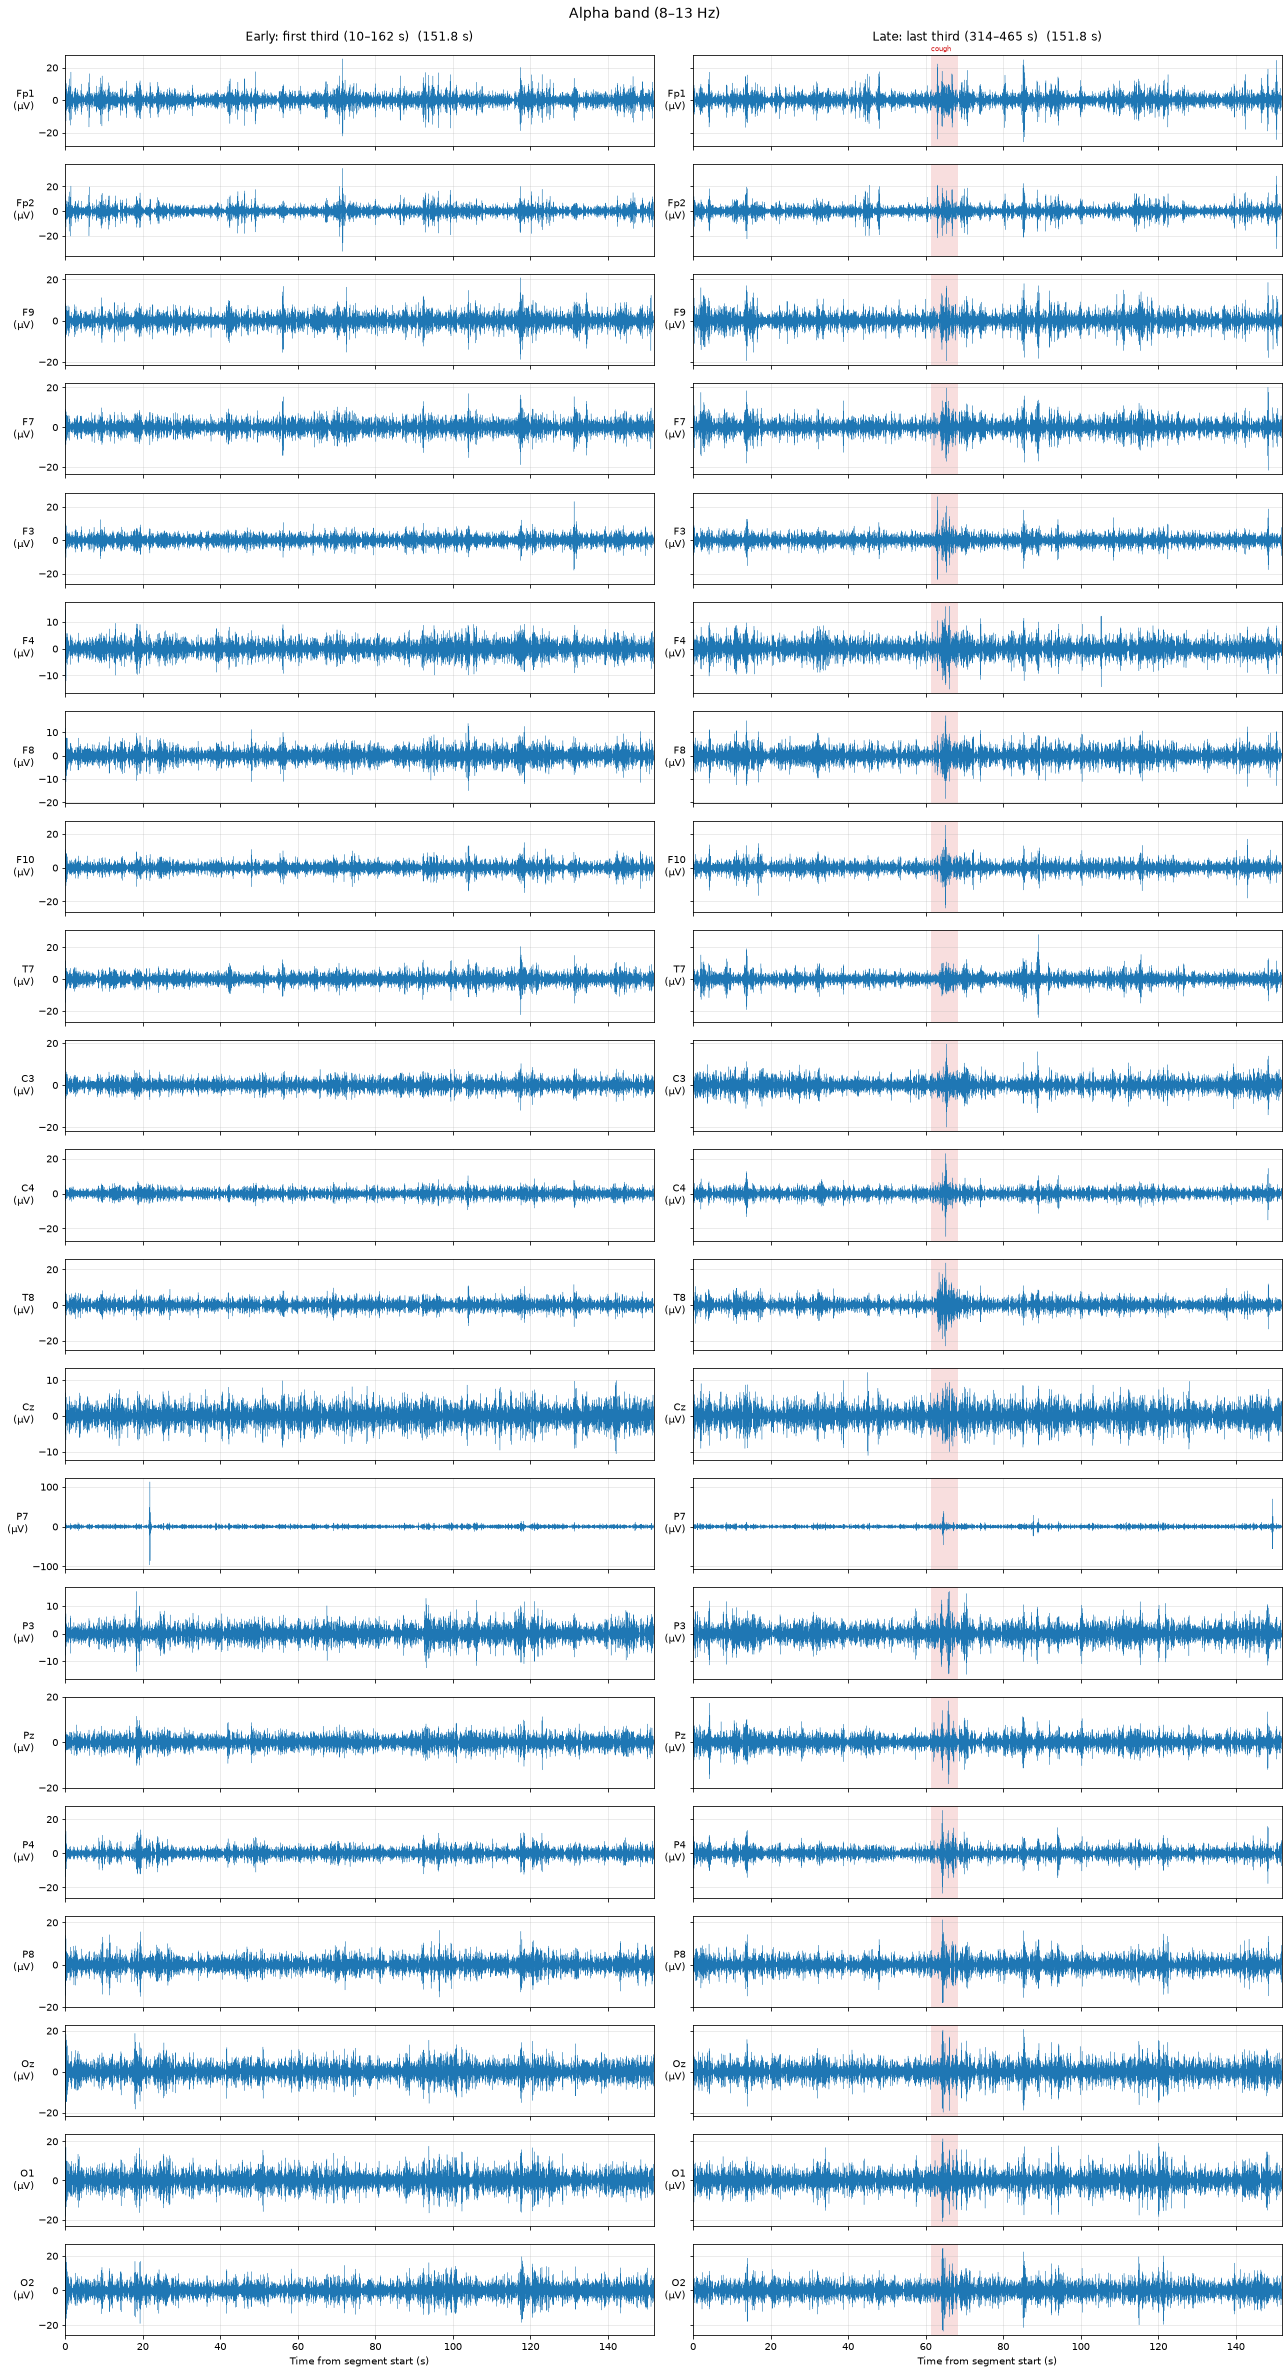

In [8]:
plot_segments([band_filter(s, 8, 13) for s in early_late], third_labels, "Alpha band (8–13 Hz)", marks=marks)

### 3.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement and muscle activity (over C3/C4 it drops while the fingers move), so it shows whether the tapping itself changed. It is a confound to watch, not a measure of effort.

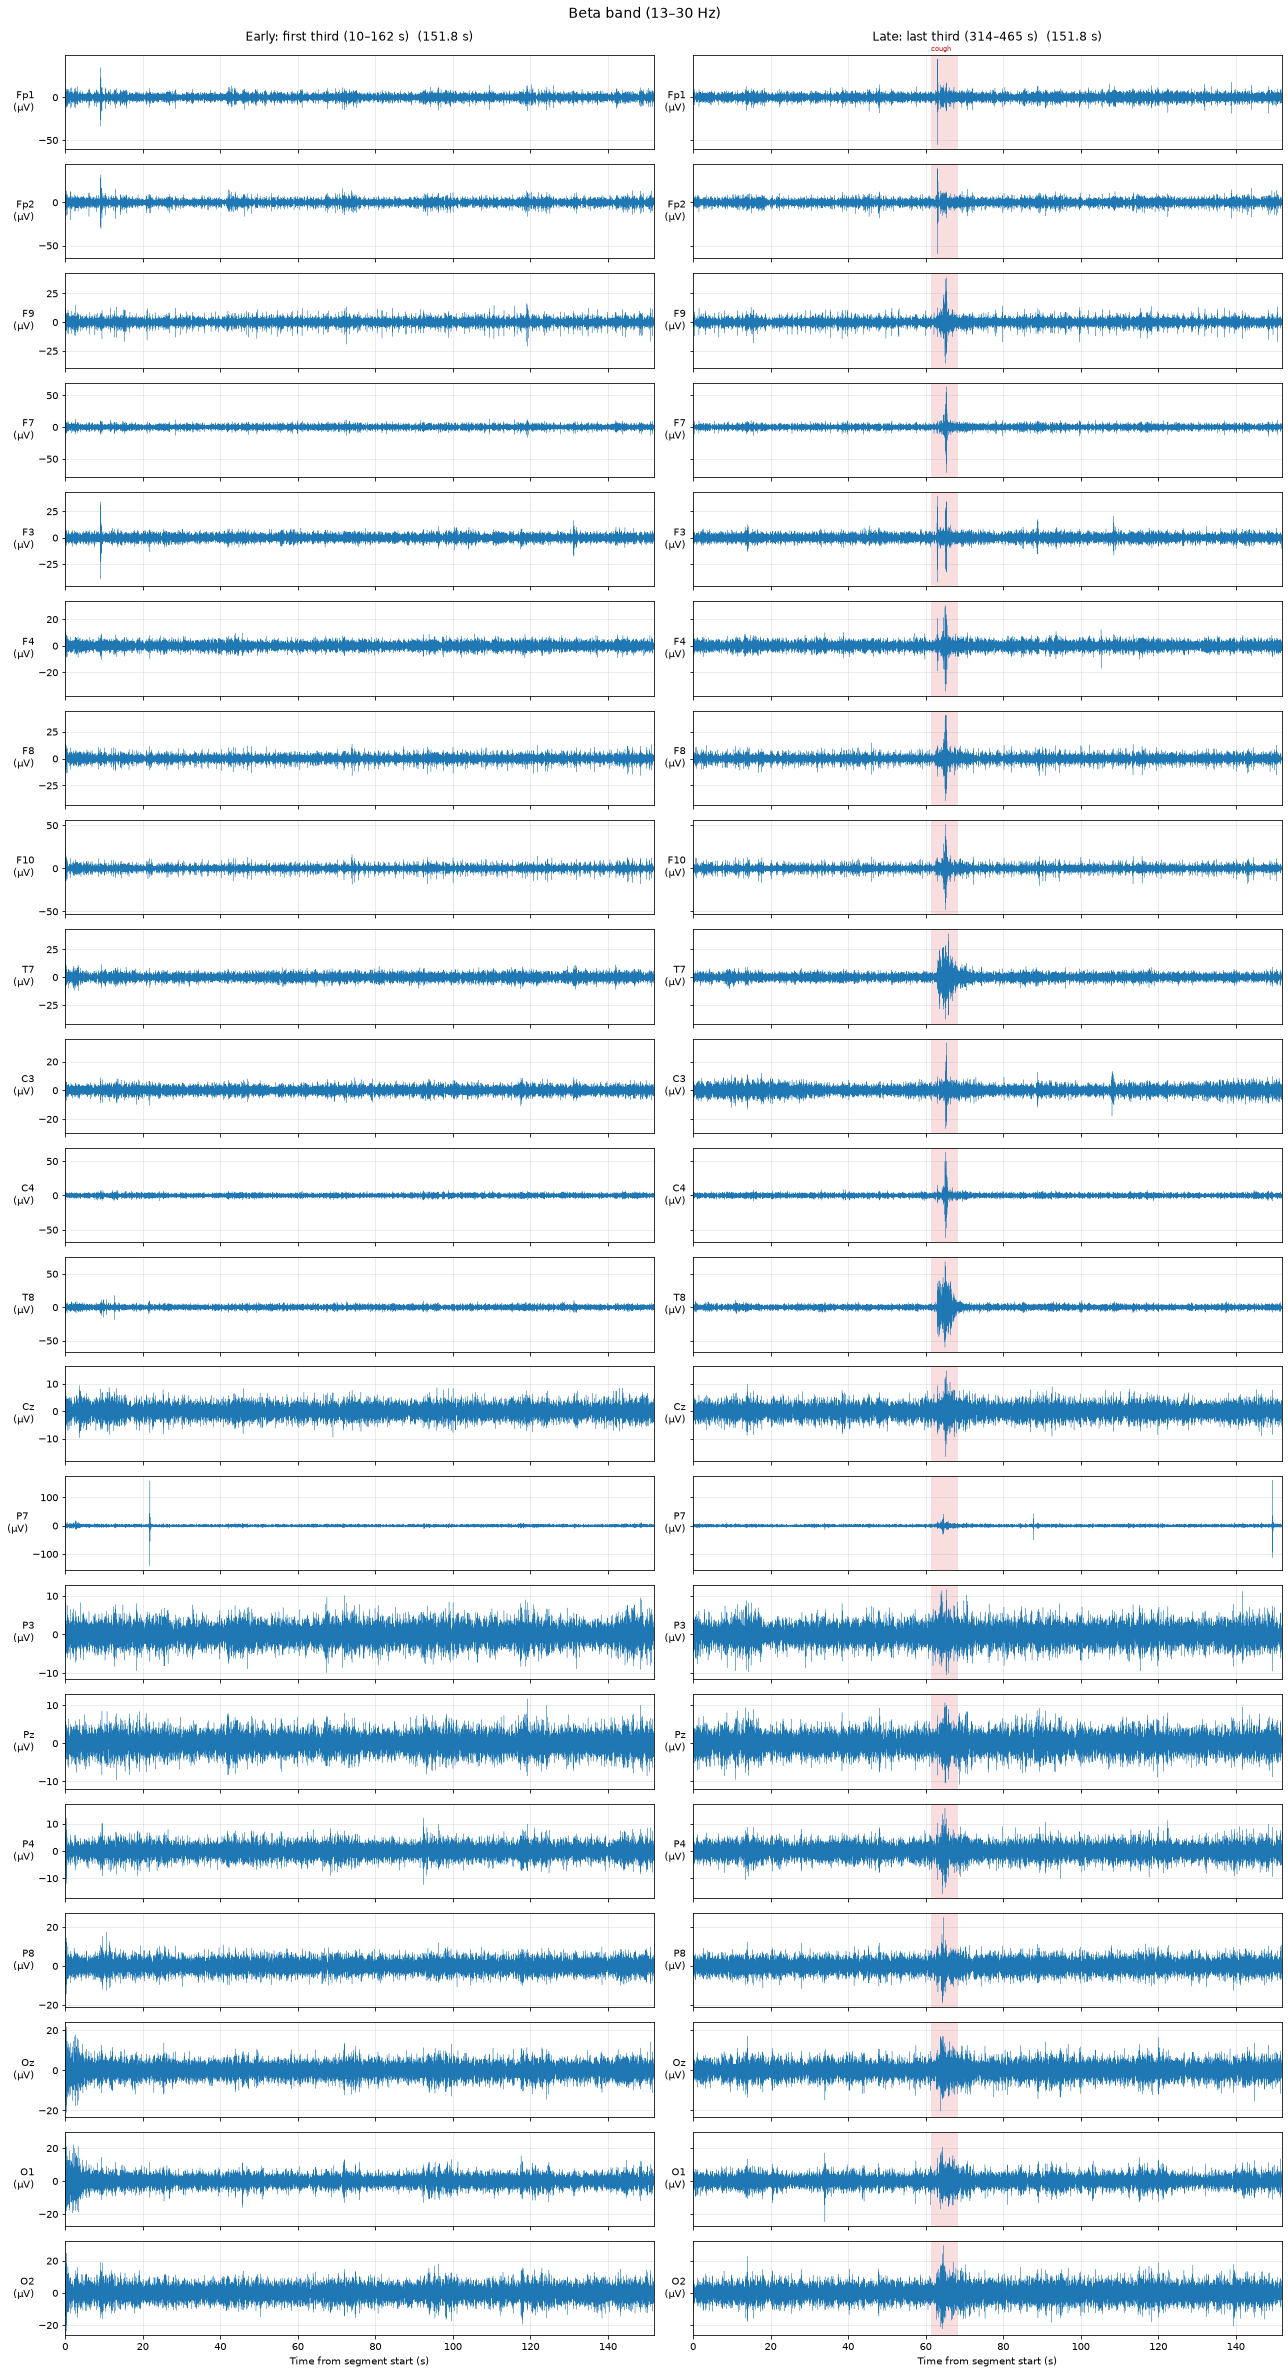

In [9]:
plot_segments([band_filter(s, 13, 30) for s in early_late], third_labels, "Beta band (13–30 Hz)", marks=marks)

### 3.5 Gamma band (30–100 Hz)

**Why this plot:** gamma on the scalp is mostly muscle activity, so it shows whether muscle tension changed over the task. It is a confound to watch, not a measure of effort.

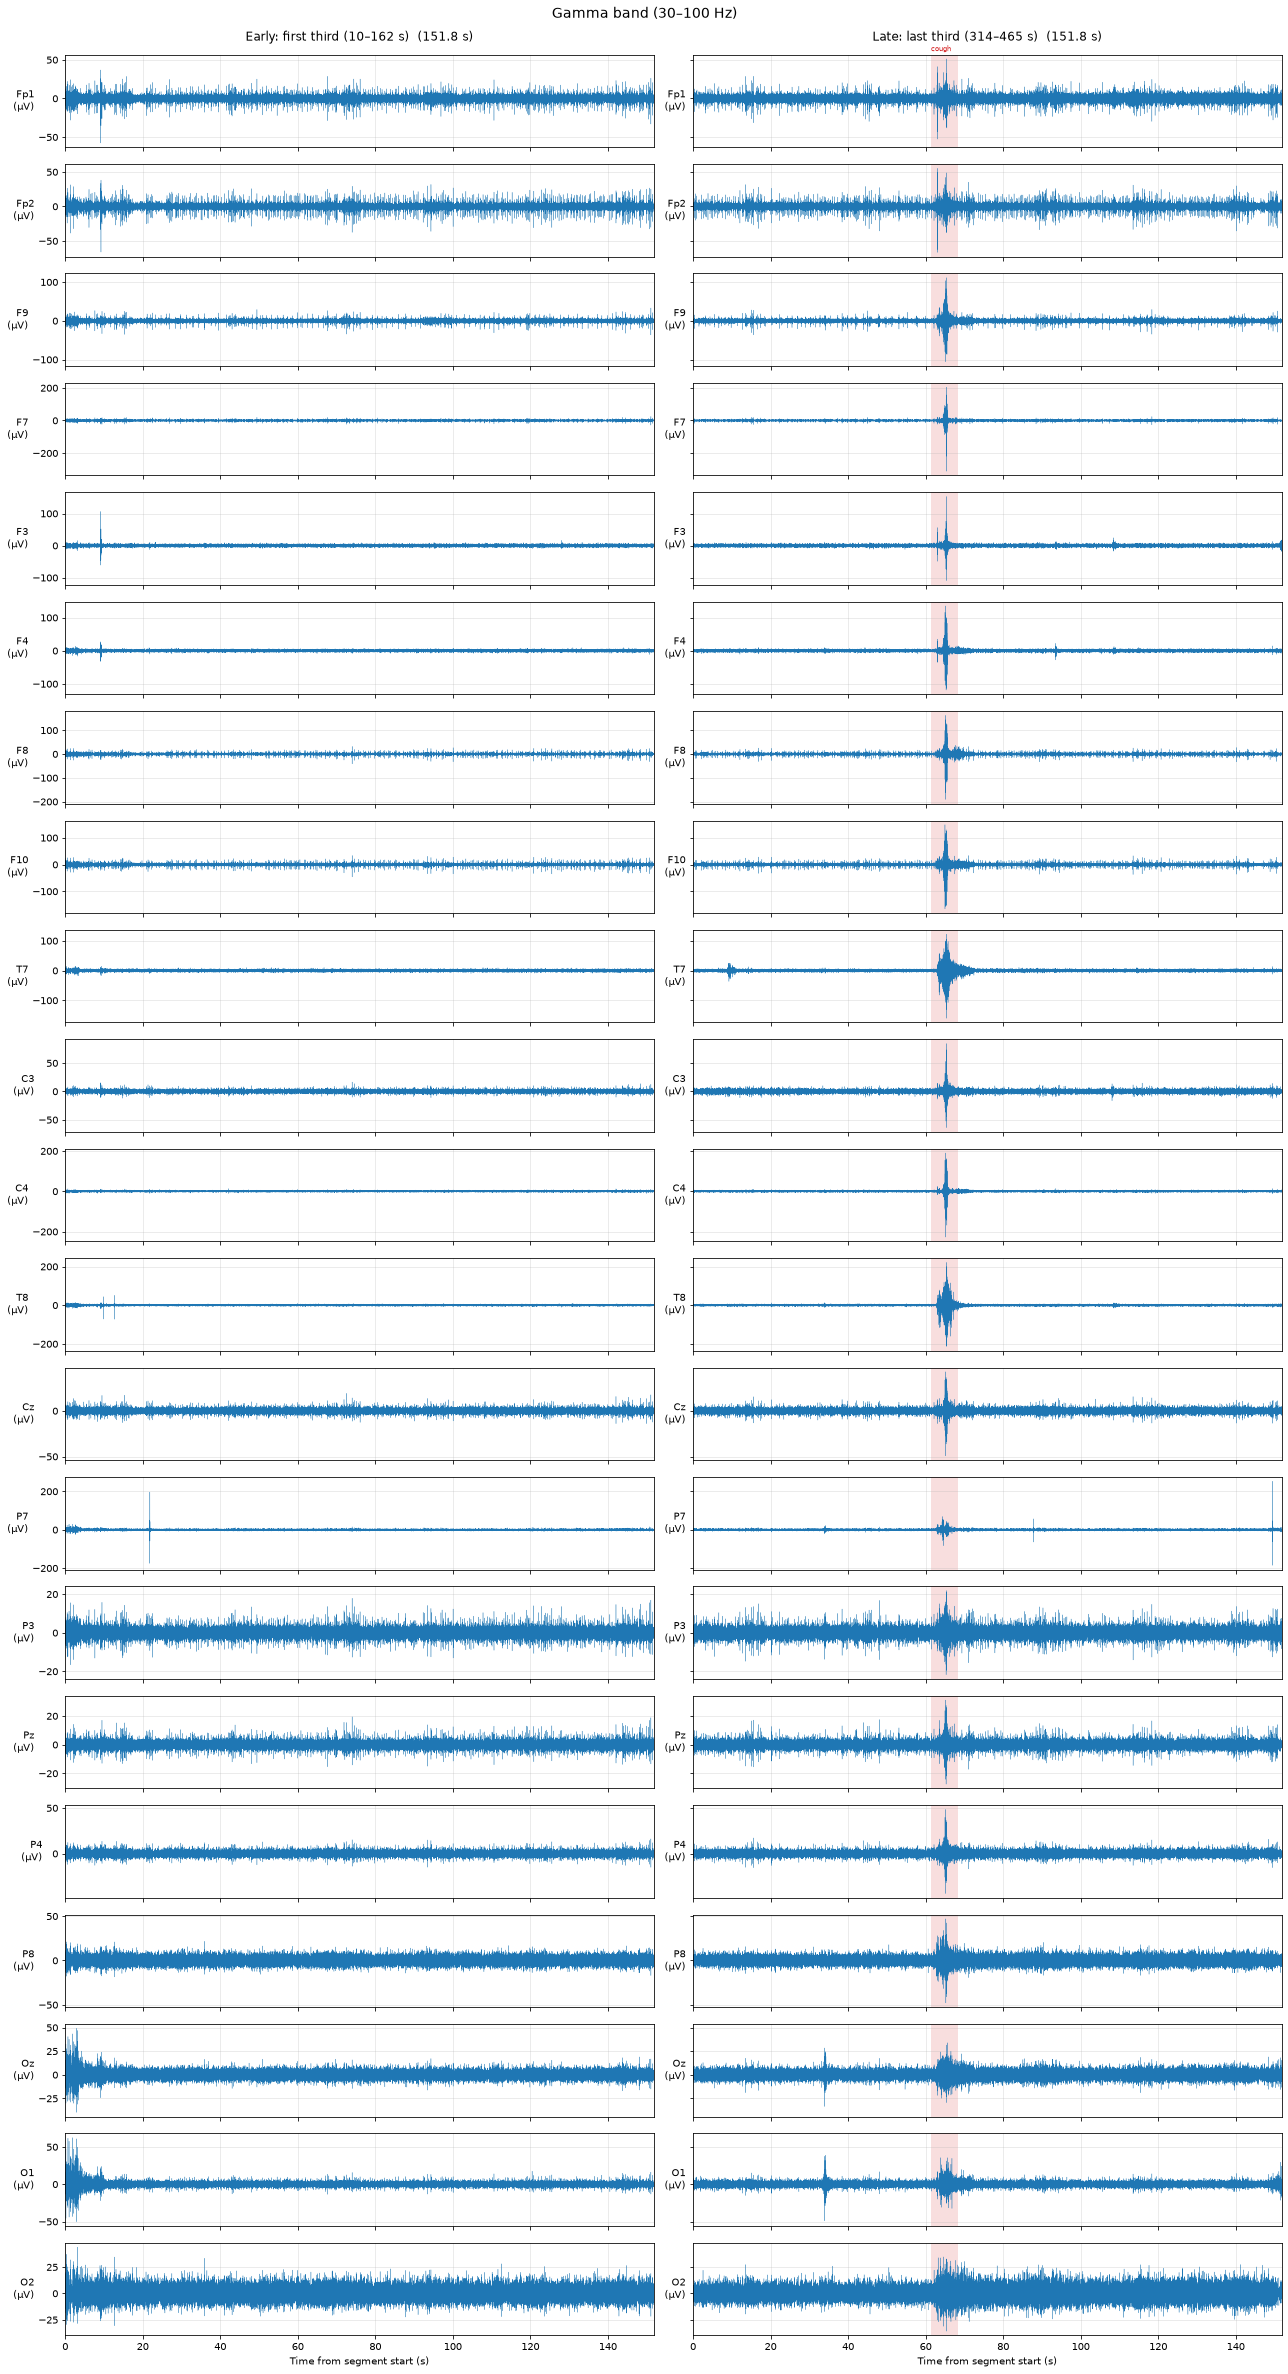

In [10]:
plot_segments([band_filter(s, 30, 99) for s in early_late], third_labels, "Gamma band (30–100 Hz)", marks=marks)

## 4. Frequency decomposition (FFT)

Welch's method (2 s Hann windows, 50% overlap), early third vs late third. Relative power is
a band's share of 4–40 Hz.

**Why these plots:** the spectra show which frequencies carry the power early and late in the
task; the bars show across the head whether theta falls and alpha rises as the sequence is learned.

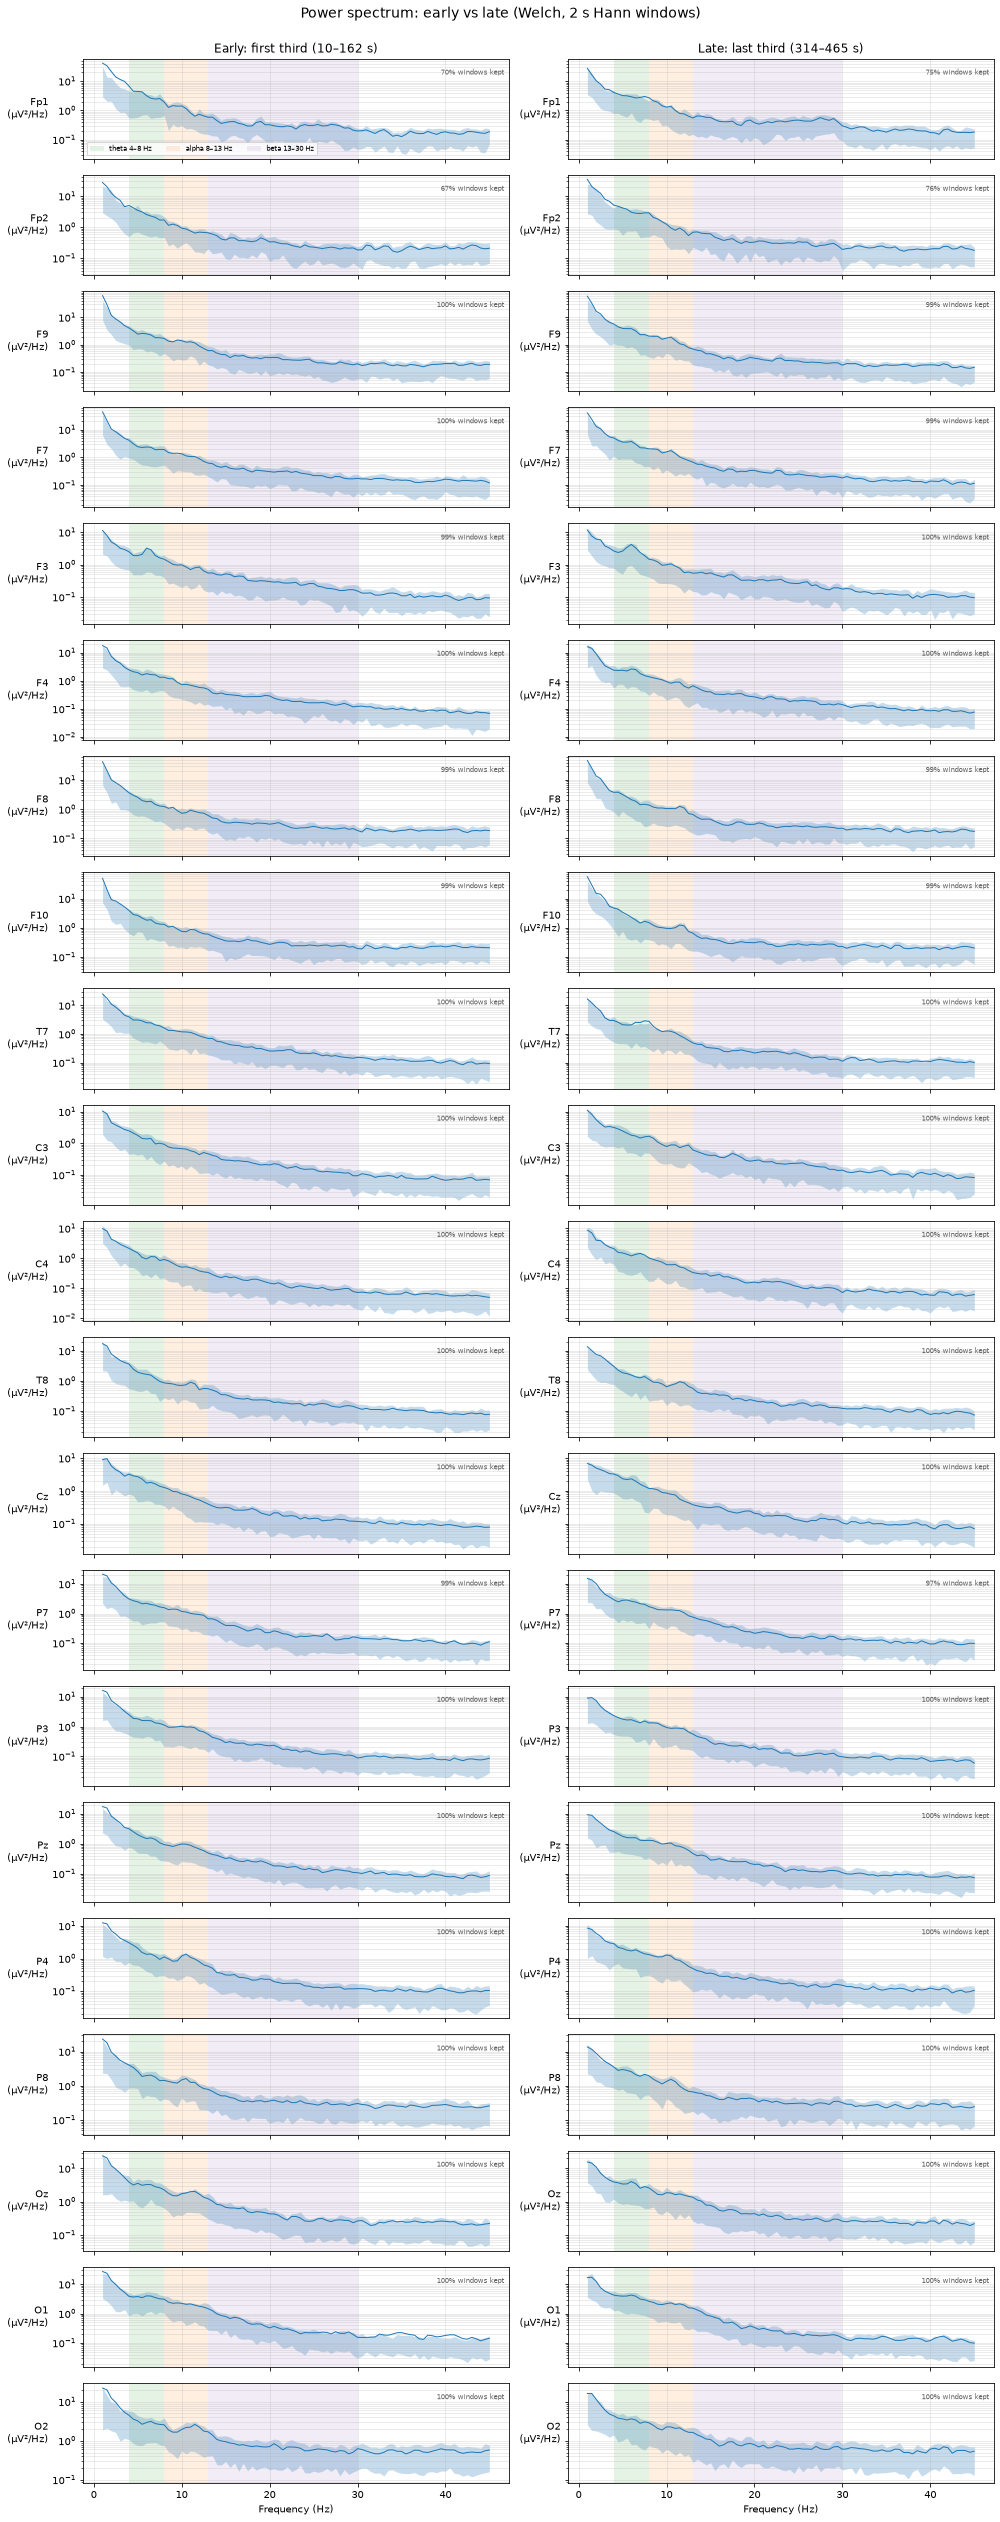

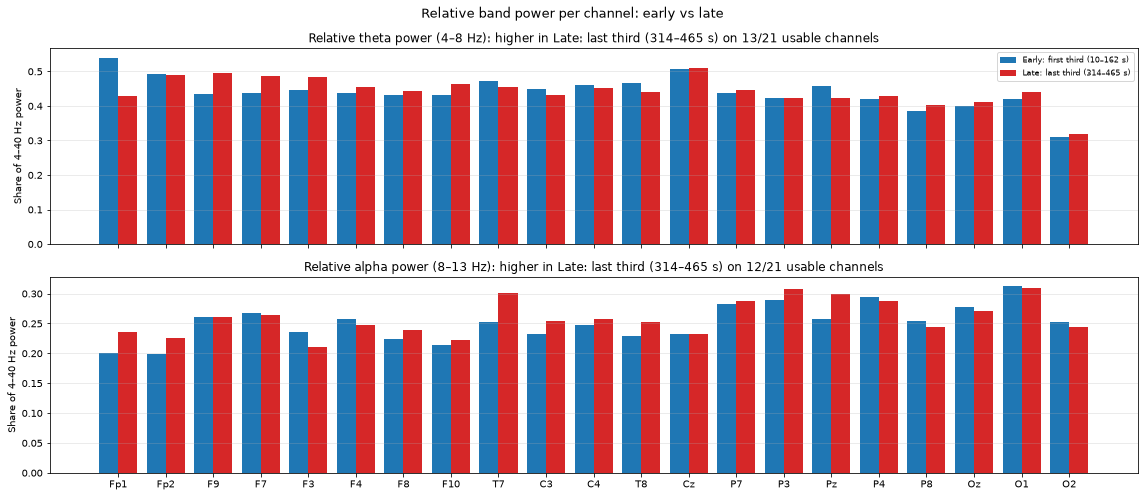

In [11]:
el_spectra = [window_spectra(s) for s in early_late]
plot_spectra(el_spectra, third_labels, "Power spectrum: early vs late (Welch, 2 s Hann windows)")
plot_relative_bars(el_spectra, third_labels, "Relative band power per channel: early vs late")

## 5. Cleaned analysis: ICA + theta/alpha above the 1/f background

As in the other notebooks: ICA with ICLabel removes components confidently (probability ≥ 0.7)
classified as eye, muscle, heart, line noise or channel noise (the cough span is left out of
the fit); FOOOF measures theta (F3+F4) and alpha (Pz) as power above the 1/f background, in dB.

ICA: 3 of 20 components removed: IC00 eye blink (0.99), IC01 eye blink (1.00), IC14 eye blink (0.77)


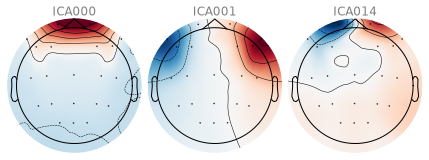

In [12]:
(task_clean,), ica_report, ica = ica_clean([task])
print(f"ICA: {int(ica_report.removed.sum())} of {len(ica_report)} components removed: "
      + ", ".join(f"{r.component} {r.label} ({r.probability:.2f})" for r in ica_report[ica_report.removed].itertuples()))
ica.plot_components(picks=ica.exclude, title="Components removed by ICLabel", show=False)
plt.show()

### 5.1 Over the course of the task

Theta above 1/f at F3+F4, alpha above 1/f at Pz and the 1/f exponent at F3+F4, for each of the
six blocks (about 76 s each). The trend is summarized with a Spearman correlation against
block number (descriptive: six blocks from one recording).

**Why this plot:** learning should show as a gradual change across the task, not just a
difference between two halves, so this shows the shape of any change over time.

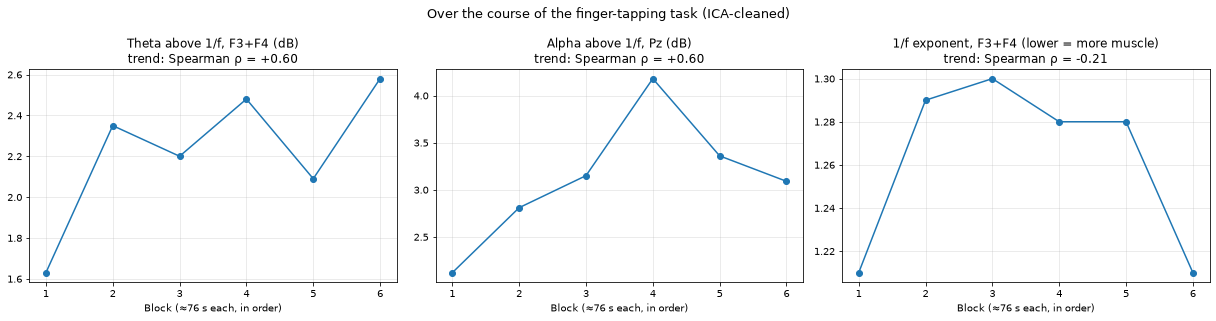

,block,theta_F3+F4_dB,alpha_Pz_dB,exponent_F3+F4,windows_clean_%
0,1: 10–86 s,1.63,2.12,1.21,97
1,2: 86–162 s,2.35,2.81,1.29,100
2,3: 162–238 s,2.20,3.15,1.30,100
3,4: 238–314 s,2.48,4.18,1.28,100
4,5: 314–390 s,2.09,3.36,1.28,100
5,6: 390–465 s,2.58,3.09,1.21,100


In [13]:
from scipy.stats import spearmanr

rows = []
for b, blk in enumerate(split(task_clean, N_BLOCKS)):
    sp = roi_spectrum(window_spectra(blk), THETA_CHANNELS)
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    rows.append({"block": block_name(b), "theta_F3+F4_dB": m["theta_db"], "alpha_Pz_dB": m["alpha_db"],
                 "exponent_F3+F4": m[f"exponent_{THETA_SITE}"], "windows_clean_%": round(100 * sp[3][-1])})
per_block = pd.DataFrame(rows).round(2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta_F3+F4_dB", "alpha_Pz_dB", "exponent_F3+F4"],
                          ["Theta above 1/f, F3+F4 (dB)", "Alpha above 1/f, Pz (dB)", "1/f exponent, F3+F4 (lower = more muscle)"]):
    rho = spearmanr(range(N_BLOCKS), per_block[col]).correlation
    ax.plot(range(1, N_BLOCKS + 1), per_block[col], "o-", color="C0")
    ax.set_xticks(range(1, N_BLOCKS + 1))
    ax.set_xlabel("Block (≈76 s each, in order)")
    ax.set_title(f"{title}\ntrend: Spearman ρ = {rho:+.2f}")
    ax.grid(alpha=0.3)
fig.suptitle("Over the course of the finger-tapping task (ICA-cleaned)", fontsize=13)
fig.tight_layout()
plt.show()
per_block

### 5.2 Early third vs late third

**Why these plots:** they compare the start and end of the task directly, with the 1/f
background separated out, which is the cleanest test of whether effort dropped as the
sequence was learned.

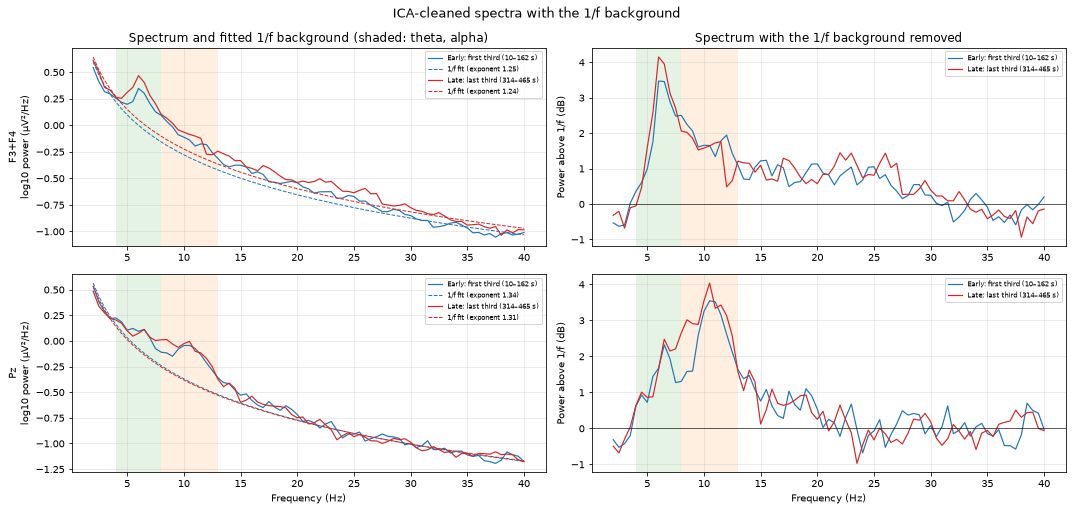

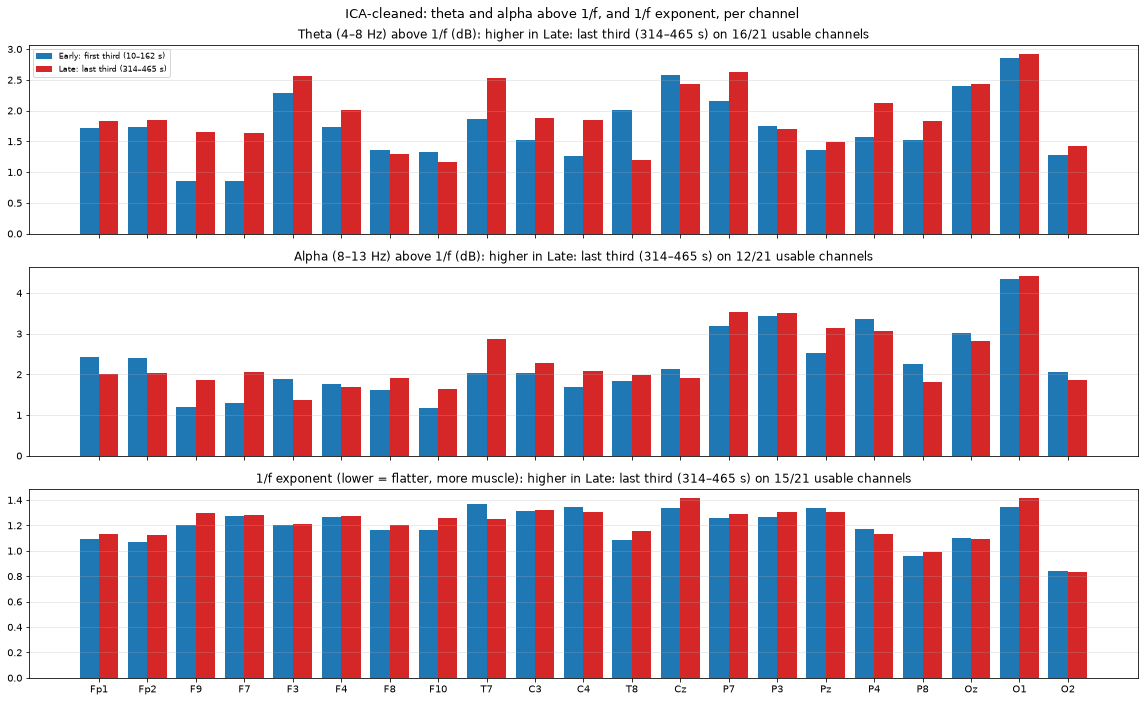

Early: first third (10–162 s): theta F3+F4 +2.00 dB, alpha Pz +2.53 dB (averaged spectrum)
Late: last third (314–465 s): theta F3+F4 +2.32 dB, alpha Pz +3.15 dB (averaged spectrum)


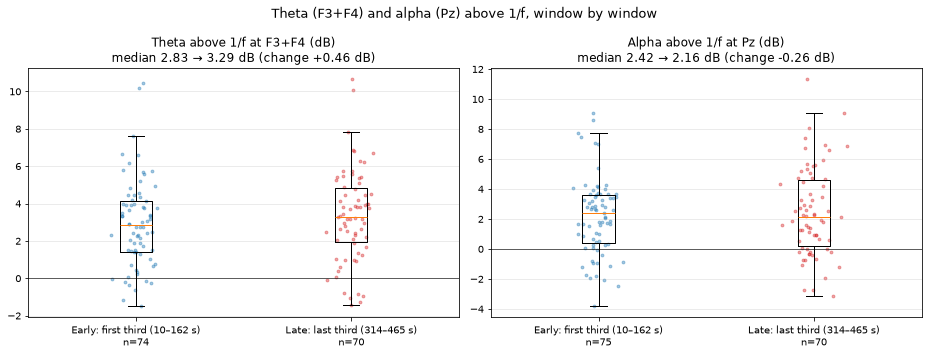

,Early: first third (10–162 s),Late: last third (314–465 s),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at F3+F4 (dB),2.83,3.29,0.46,0.11,0.89,74 / 70
Alpha above 1/f at Pz (dB),2.42,2.16,-0.26,0.38,0.62,75 / 70


In [14]:
clean_thirds = split(task_clean, 3)
clean_el = [roi_spectrum(window_spectra(s), THETA_CHANNELS) for s in (clean_thirds[0], clean_thirds[2])]
plot_fooof_fits(clean_el, third_labels, "ICA-cleaned spectra with the 1/f background", channels=(THETA_SITE, ALPHA_SITE))
plot_periodic_bars([(p[:, :-1], f, c[:-1], k[:-1]) for p, f, c, k in clean_el], third_labels,
                   "ICA-cleaned: theta and alpha above 1/f, and 1/f exponent, per channel")
for label, sp in zip(third_labels, clean_el):
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    print(f"{label}: theta F3+F4 {m['theta_db']:+.2f} dB, alpha Pz {m['alpha_db']:+.2f} dB (averaged spectrum)")
clean_el_nonoverlap = [roi_spectrum(window_spectra(s, overlap=0.0), THETA_CHANNELS) for s in (clean_thirds[0], clean_thirds[2])]
periodic_workload_comparison(clean_el_nonoverlap, third_labels, "Theta (F3+F4) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE)

## 6. Results: does the data support the hypothesis?

**No. Frontal theta did not fall as the sequence was practised. It rose, mostly between the
first block and the rest, and alpha rose then fell. Neither pattern looks like effort steadily
dropping with learning.**

| Measure (ICA-cleaned, above 1/f) | Early third (10–162 s) | Late third (314–465 s) | Hypothesis (learning) predicts | Result |
|---|---|---|---|---|
| Theta at F3+F4, averaged spectrum | +2.00 dB | +2.32 dB | lower late | **Higher late** (+0.3 dB) |
| Theta at F3+F4, window median | +2.83 dB | +3.29 dB | lower late | **Higher late** (+0.5 dB, descriptive p = 0.11) |
| Alpha at Pz, averaged spectrum | +2.53 dB | +3.15 dB | higher late | Higher late (+0.6 dB) |
| Alpha at Pz, window median | +2.42 dB | +2.16 dB | higher late | Lower late (−0.3 dB): inconsistent |
| Theta trend over 6 blocks | | | falling | **Rising** (Spearman ρ = +0.60): block 1 1.6 dB, blocks 2–6 2.1–2.6 dB |
| Alpha trend over 6 blocks | | | rising | Rises to block 4 (4.2 dB), then falls back (3.1 dB) |
| 1/f exponent over 6 blocks | | | | Stable (1.21–1.30): muscle activity didn't change much |

How to read this:
- **Theta rising rather than falling** doesn't fit "less effort as the sequence is learned". It
  fits time on task: theta has been found to rise with practice and extended testing
  ([Gevins et al., 1997](https://pubmed.ncbi.nlm.nih.gov/9177767/)), which is the same
  learning-vs-fatigue ambiguity this design can't resolve without performance data.
- **The 1/f exponent is stable,** so unlike Sessions 1 and 3.1 the theta change here isn't
  accompanied by a change in muscle activity, which makes it more likely to be brain activity.
- **Alpha's rise-then-fall** doesn't match either a steady learning effect or steady fatigue.
- **Clock alignment:** the session notes were about 12 s ahead of the eego laptop; aligning on
  the cough puts the task start at 10 s and the noted end 0.5 s after the recording stops,
  so the alignment is consistent. The cough (375–382 s) is excluded.
- **Fz couldn't be used** (saturated electrode), so frontal theta comes from F3+F4.

**What would make this testable:** tapping speed and errors per block (to confirm learning
happened and when), a rest recording before and after, and a short block with a new sequence at
the end. If theta drops for the practised sequence relative to a new one, that is learning, not fatigue.